In [1]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,f1_score,classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
import numpy as np 
import pandas as  pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load Data

In [3]:
data = pd.read_csv('heart.csv')
data.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
# EDA

In [5]:
try:
    import sheryanalysis as sh
    sh.analyze(data)
except ImportError:
    print('sheryanalysis not installed (pip install sheryanalysis); skipping')


🔍 Basic Analysis Report
------------------------------------------------------------
📏 Shape: (918, 12)
🧱 Columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

✅ No null values found

🔠 Categorical Columns: ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'HeartDisease']

🔢 Numerical Columns: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']


In [6]:
data.shape

(918, 12)

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [8]:
data.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:
data['HeartDisease'].value_counts()

HeartDisease
1    508
0    410
Name: count, dtype: int64

<Axes: xlabel='HeartDisease'>

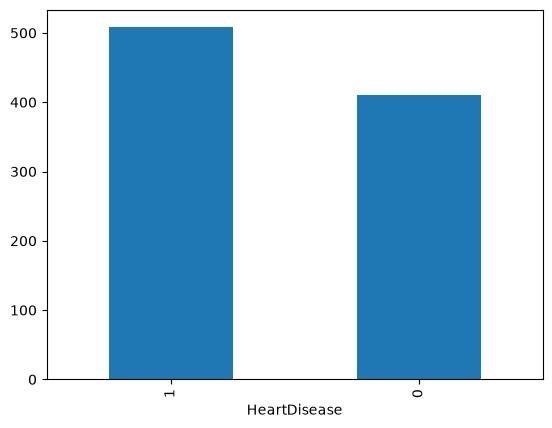

In [11]:
data['HeartDisease'].value_counts().plot(kind='bar')

In [12]:
data.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

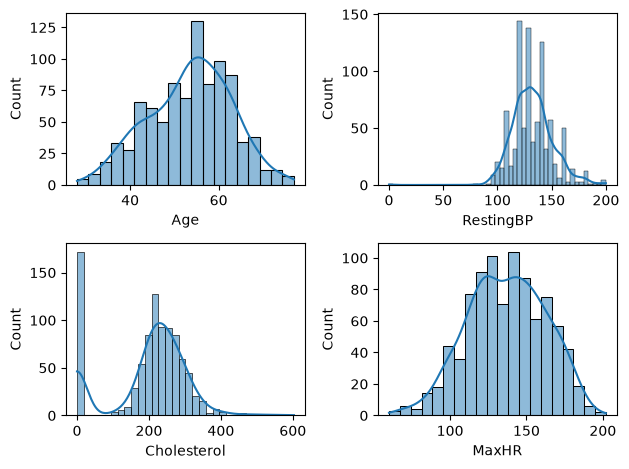

In [13]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(data[var],kde = True) 

plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)
plt.tight_layout()

In [14]:
data['Cholesterol'].value_counts()

Cholesterol
0      172
254     11
223     10
220     10
211      9
      ... 
353      1
278      1
157      1
176      1
131      1
Name: count, Length: 222, dtype: int64

In [15]:
ch_mean=data.loc[data['Cholesterol']!=0,'Cholesterol'].mean()
ch_mean

np.float64(244.6353887399464)

In [16]:
# replacing o by mean of Cholesterol !=0

In [17]:
data['Cholesterol']=data['Cholesterol'].replace(0,ch_mean)
data['Cholesterol']=data['Cholesterol'].round(2)

In [18]:
# replacing o by mean of RestingBP !=0

In [19]:
restingbp_mean=data.loc[data['RestingBP']!=0,'RestingBP'].mean()
restingbp_mean

np.float64(132.54089422028352)

In [20]:
data['RestingBP']=data['RestingBP'].replace(0,restingbp_mean)
data['RestingBP']=data['RestingBP'].round(2)

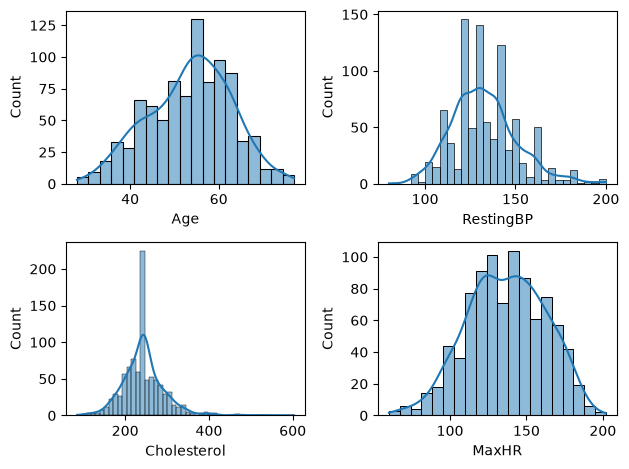

In [21]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(data[var],kde = True) 

plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)
plt.tight_layout()

<Axes: xlabel='Sex', ylabel='count'>

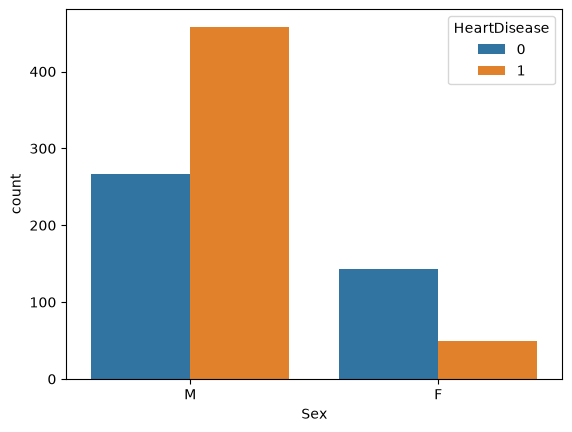

In [22]:
sns.countplot(x = data['Sex'],hue=data['HeartDisease'])

<Axes: xlabel='ChestPainType', ylabel='count'>

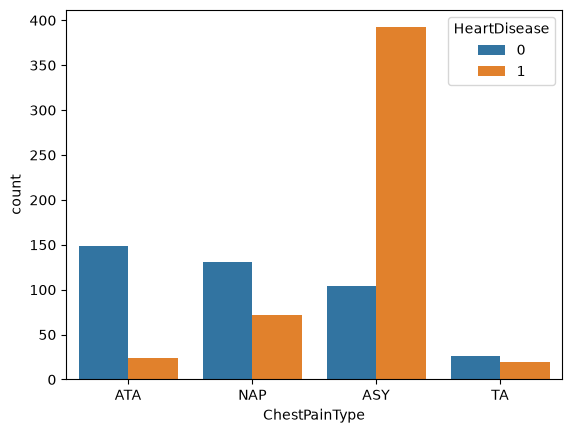

In [23]:
sns.countplot(x = data['ChestPainType'],hue=data['HeartDisease'])

<Axes: xlabel='FastingBS', ylabel='count'>

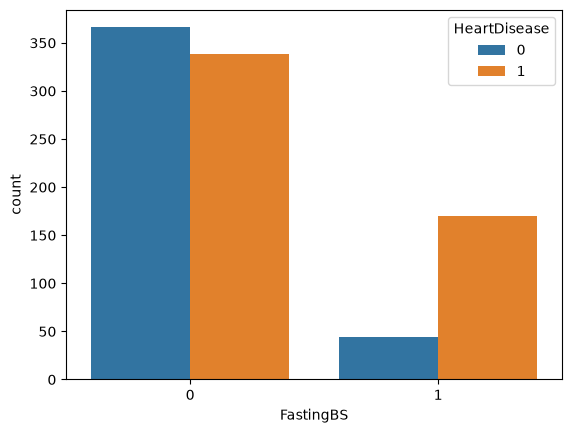

In [24]:
sns.countplot(x=data['FastingBS'],hue=data['HeartDisease'])

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

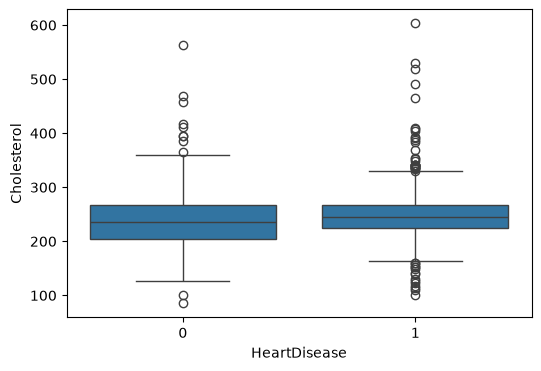

In [25]:
plt.figure(figsize=(6,4))
sns.boxplot(x= 'HeartDisease',y = 'Cholesterol',data=data)

<Axes: xlabel='HeartDisease', ylabel='Age'>

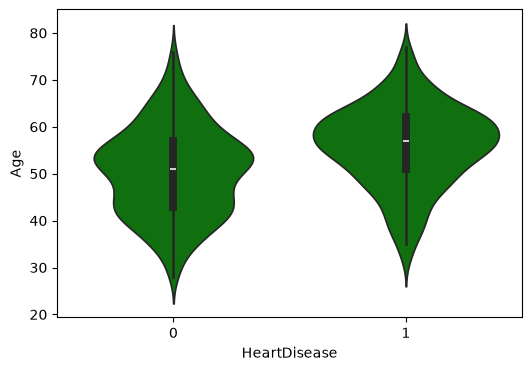

In [26]:
plt.figure(figsize=(6,4))
sns.violinplot(x= 'HeartDisease',y = 'Age',color='green',data=data)

<Axes: >

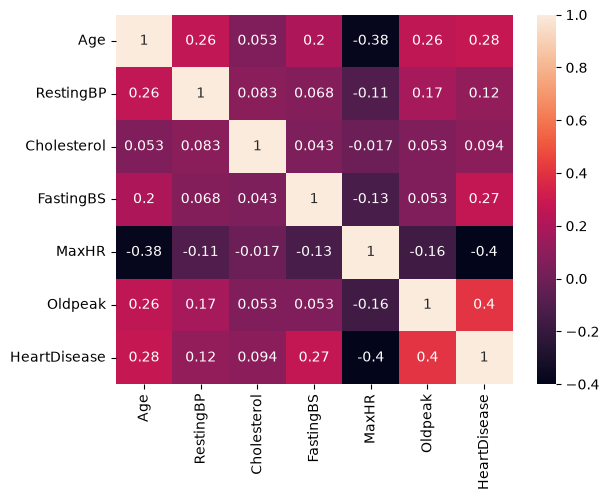

In [27]:
sns.heatmap(data.corr(numeric_only=True),annot=True)

In [28]:
# Encode Data 

In [29]:
en_data = pd.get_dummies(data,drop_first=True)
en_data

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160.0,180.0,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130.0,283.0,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138.0,214.0,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150.0,195.0,0,122,0.0,0,True,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110.0,264.0,0,132,1.2,1,True,False,False,True,True,False,False,True,False
914,68,144.0,193.0,1,141,3.4,1,True,False,False,False,True,False,False,True,False
915,57,130.0,131.0,0,115,1.2,1,True,False,False,False,True,False,True,True,False
916,57,130.0,236.0,0,174,0.0,1,False,True,False,False,False,False,False,True,False


In [30]:
# convert only bool dummy columns (astype(int) on everything would truncate Oldpeak/Cholesterol decimals)
bool_cols = en_data.select_dtypes(include='bool').columns
en_data[bool_cols] = en_data[bool_cols].astype(int)

In [31]:
en_data

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,0,1,1,0,0,1,0,0,0,1
1,49,160.0,180.0,0,156,1.0,1,0,0,1,0,1,0,0,1,0
2,37,130.0,283.0,0,98,0.0,0,1,1,0,0,0,1,0,0,1
3,48,138.0,214.0,0,108,1.5,1,0,0,0,0,1,0,1,1,0
4,54,150.0,195.0,0,122,0.0,0,1,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110.0,264.0,0,132,1.2,1,1,0,0,1,1,0,0,1,0
914,68,144.0,193.0,1,141,3.4,1,1,0,0,0,1,0,0,1,0
915,57,130.0,131.0,0,115,1.2,1,1,0,0,0,1,0,1,1,0
916,57,130.0,236.0,0,174,0.0,1,0,1,0,0,0,0,0,1,0


In [32]:
from sklearn.preprocessing import StandardScaler

In [33]:
ssc = StandardScaler()
numerical_columns   =   ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
en_data[numerical_columns]  = ssc.fit_transform(en_data[numerical_columns])

In [34]:
en_data.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.414853,0.832513,0,1.382928,-0.832432,0,1,1,0,0,1,0,0,0,1
1,-0.478484,1.527192,-1.212938,0,0.754157,0.105664,1,0,0,1,0,1,0,0,1,0
2,-1.751359,-0.141317,0.719919,0,-1.525138,-0.832432,0,1,1,0,0,0,1,0,0,1
3,-0.584556,0.303619,-0.574908,0,-1.132156,0.574711,1,0,0,0,0,1,0,1,1,0
4,0.051881,0.971022,-0.931454,0,-0.581981,-0.832432,0,1,0,1,0,1,0,0,0,1


In [35]:
x = en_data.drop('HeartDisease',axis=1)
y = en_data['HeartDisease']

In [36]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [37]:
models = {
    "logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(),
    "naive_bayes": GaussianNB(),
    "DecisionTree": DecisionTreeClassifier(),
    "SVM": SVC(),
    "Random Forest": RandomForestClassifier()
}

In [38]:
result = []

In [39]:
for name,model in models.items():
    model.fit(x_train,y_train)
    y_pred = model.predict(x_test)
    acc = accuracy_score(y_test,y_pred)
    f1 = f1_score(y_test,y_pred)
    result.append({
        
        'model':name,
        'accuracy':round(acc,4),
        'f1_score':round(f1,4)
            
    })

In [40]:
result

[{'model': 'logistic Regression', 'accuracy': 0.8641, 'f1_score': 0.8792},
 {'model': 'KNN', 'accuracy': 0.8587, 'f1_score': 0.8785},
 {'model': 'naive_bayes', 'accuracy': 0.8478, 'f1_score': 0.8614},
 {'model': 'DecisionTree', 'accuracy': 0.8152, 'f1_score': 0.8333},
 {'model': 'SVM', 'accuracy': 0.837, 'f1_score': 0.8585},
 {'model': 'Random Forest', 'accuracy': 0.8641, 'f1_score': 0.8815}]

In [41]:
# Save Pickle File 

In [43]:
import joblib
joblib.dump(models['Random Forest'],'RandomForestClassifier.pkl')
joblib.dump(ssc,'ssc.pkl')
joblib.dump(x.columns.tolist(),'columns.pkl')

['columns.pkl']